# Phase 3: EDA and Feature Engineering

This notebook explores the cleaned data from Phase 2 and builds the modelling dataset for Phase 4.

**The task (from Phase 1).** On day `d` of a billing month, project that month's end bill for each household,
with a prediction interval. The kWh used on days 1..d is already known; the model predicts the kWh for days
d+1..end of the month and adds it to the known part.

**The bill is a computed proxy**: kWh × 14.228 p/kWh (the published standard tariff), not a real invoice.
Because the bill is kWh times a fixed rate, any correlation "with the bill" is the same number as the
correlation with kWh.

**Scope: standard-tariff households only.** Time-of-use households paid different prices by time of day in 2013,
so the flat-rate bill proxy is wrong for them. They are left for the stretch goal.

Like Phase 2, we use **DuckDB** for anything large and only bring small results into pandas.

## 1. Setup

All paths, the tariff rate, the candidate values of `d` and every threshold live in this cell, so later cells
contain no magic numbers.

In [1]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap

# Find the repo root (the folder with pyproject.toml), so the paths work wherever the notebook runs
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())

# Inputs: Phase 2 outputs (read only)
DAILY_PARQUET = ROOT / "data/processed/daily.parquet"
MONTHLY_PARQUET = ROOT / "data/processed/monthly.parquet"

# Outputs
FEATURES_PARQUET = ROOT / "data/processed/features_day_d.parquet"
FIG_DIR = ROOT / "reports/figures"

# Problem settings
TARIFF_SCOPE = "Std"              # standard flat-rate households only (ToU = stretch goal)
TARIFF_GBP_PER_KWH = 0.14228      # 14.228 p/kWh, London Datastore standard tariff
D_VALUES = [7, 14, 21]            # candidate forecast days; Phase 4 picks the final one
CURVE_MAX_D = 28                  # day-by-day curves stop at 28, the length of the shortest month

# EDA thresholds
IQR_K = 1.5                       # Tukey fence for the pooled outlier check
ROBUST_Z_LIMIT = 3.5              # within-household outlier cutoff on the robust (median/MAD) z-score
MAD_TO_Z = 0.6745                 # makes the MAD z-score comparable to a normal z-score (Iglewicz & Hoaglin)
MIN_MONTHS_PER_HOUSEHOLD = 6      # minimum history for per-household statistics
TEMP_BIN_C = 2                    # width of the temperature bins in the daily plot
HIST_CLIP_PCT = 0.995       # histograms stop at this percentile so the long tail doesn't flatten them
CORR_D = 14                       # d used for the feature correlation heatmap

FIG_DPI = 200
FIG_DIR.mkdir(parents=True, exist_ok=True)

con = duckdb.connect()
con.execute("SET enable_progress_bar = false")

Every figure uses the same look: a fixed colour order (the first colour is always the main series), light gridlines,
no top or right border. `save` writes the figure to `reports/figures/`, where the report picks it up.

In [2]:
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]   # fixed categorical order: blue, orange, aqua, yellow
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"
# Diverging map for correlations: orange (negative), gray (zero), blue (positive)
CORR_CMAP = LinearSegmentedColormap.from_list("corr", ["#d95926", "#f0efec", "#2a78d6"])

plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.prop_cycle": plt.cycler(color=COLORS),
    "font.size": 10, "axes.titlesize": 11, "lines.linewidth": 2,
})


def save(fig, name):
    """Save a figure to reports/figures/ and show it."""
    fig.savefig(FIG_DIR / name, dpi=FIG_DPI, bbox_inches="tight")
    plt.show()
    print("Saved", (FIG_DIR / name).relative_to(ROOT))

## 2. Scope: keep standard-tariff households

We filter on `tariff = 'Std'` **before** any statistics or lags, so every number in this notebook describes the
population we will model. No household changes tariff during the trial, so filtering on the household's tariff
keeps or drops whole histories.

In [3]:
con.execute(f"CREATE OR REPLACE VIEW daily_all   AS SELECT * FROM '{DAILY_PARQUET}'")
con.execute(f"CREATE OR REPLACE VIEW monthly_all AS SELECT * FROM '{MONTHLY_PARQUET}'")

# Households whose tariff changes would be split by the filter; there should be none
switchers = con.sql("SELECT count(*) FROM (SELECT LCLid FROM monthly_all GROUP BY 1 HAVING count(DISTINCT tariff) > 1)").fetchone()[0]
print("Households with more than one tariff:", switchers)

con.execute(f"CREATE OR REPLACE VIEW daily   AS SELECT * FROM daily_all   WHERE tariff = '{TARIFF_SCOPE}'")
con.execute(f"CREATE OR REPLACE VIEW monthly AS SELECT * FROM monthly_all WHERE tariff = '{TARIFF_SCOPE}'")

con.sql("""
    SELECT 'before filter' AS stage,
           (SELECT count(*) FROM monthly_all)             AS household_months,
           (SELECT count(DISTINCT LCLid) FROM monthly_all) AS households,
           (SELECT count(*) FROM daily_all)               AS household_days
    UNION ALL
    SELECT 'after filter (Std)',
           (SELECT count(*) FROM monthly),
           (SELECT count(DISTINCT LCLid) FROM monthly),
           (SELECT count(*) FROM daily)
""").df()

Households with more than one tariff: 0


,stage,household_months,households,household_days
0,before filter,106225,5548,3239805
1,after filter (Std),84807,4428,2586554


The filter keeps **84,807 of 106,225 household-months** and **4,428 of 5,548 households**, as expected from the
first-pass tariff summary. Since every remaining household has the same tariff, the tariff indicator is constant
and is dropped from the feature set.

## 3. Monthly EDA

The first pass explored `monthly.parquet` across both tariffs. We repeat the useful parts on the Std households.

### 3.1 Descriptive statistics

`filled_slots` counts half hours that Phase 2 filled in (interpolated or estimated), out of about 1,460 per month.

In [4]:
STAT_COLUMNS = ["kwh", "bill_gbp", "temp_mean", "days", "filled_slots"]

desc = con.sql(" UNION ALL ".join(f"""
    SELECT '{c}' AS variable,
           avg({c}) AS mean, median({c}) AS median, stddev_samp({c}) AS sd,
           min({c}) AS min, max({c}) AS max, count(*) - count({c}) AS missing
    FROM monthly""" for c in STAT_COLUMNS)).df()
desc.round(2)

,variable,mean,median,sd,min,max,missing
0,kwh,315.96,250.29,261.81,1.29,6385.89,0
1,bill_gbp,44.95,35.61,37.25,0.18,908.58,0
2,temp_mean,11.01,10.96,5.04,3.80,20.04,0
3,days,30.50,31.00,0.75,28.00,31.00,0
4,filled_slots,2.30,0.00,12.83,0.00,146.00,0


In [5]:
con.sql("""
    WITH per_household AS (SELECT LCLid, count(*) AS months FROM monthly GROUP BY 1)
    SELECT min(months) AS min_months, median(months) AS median_months, round(avg(months), 2) AS mean_months,
           max(months) AS max_months,
           count(*) FILTER (WHERE months >= 12) AS households_with_12_plus
    FROM per_household
""").df()

,min_months,median_months,mean_months,max_months,households_with_12_plus
0,1,20.0,19.15,26,4244


Monthly kWh is strongly right-skewed: the mean sits well above the median and the maximum is about 25 times the
median. Bills follow exactly, since they are kWh times a constant. There are no missing values.

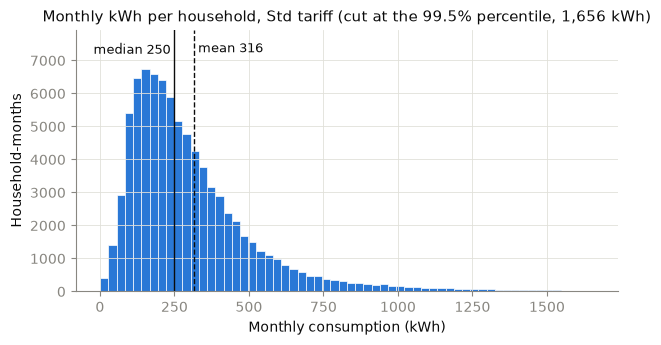

Saved reports/figures/p3_monthly_kwh_hist.png


In [6]:
kwh = con.sql("SELECT kwh FROM monthly").df()["kwh"]
clip = kwh.quantile(HIST_CLIP_PCT)

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.hist(kwh[kwh <= clip], bins=60, color=COLORS[0], edgecolor="white", linewidth=0.5)
ax.set_ylim(top=ax.get_ylim()[1] * 1.12)   # headroom so the labels sit above the bars
# Median label sits left of its line and mean label right of its line, so they never overlap
for value, label, style, align in [(kwh.median(), "median", "-", "right"), (kwh.mean(), "mean", "--", "left")]:
    ax.axvline(value, color=INK, linestyle=style, linewidth=1)
    ax.text(value, ax.get_ylim()[1] * 0.95, f" {label} {value:,.0f} ", fontsize=9, va="top", ha=align)
ax.set_xlabel("Monthly consumption (kWh)")
ax.set_ylabel("Household-months")
ax.set_title(f"Monthly kWh per household, Std tariff (cut at the {HIST_CLIP_PCT:.1%} percentile, {clip:,.0f} kWh)")
save(fig, "p3_monthly_kwh_hist.png")

### 3.2 Seasonality and temperature

We average kWh across households for each calendar month and plot it above the month's mean temperature.
The two are separate panels on purpose: two y-scales on one chart make the relationship look as strong or weak
as the axis limits allow.

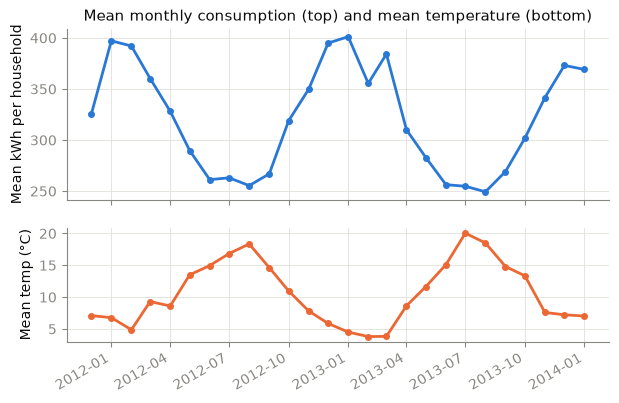

Saved reports/figures/p3_monthly_trend_temp.png


,0,1,2,3,4,5,6,7,8,9,...,16,17,18,19,20,21,22,23,24,25
month,2011-12-01 00:00:00,2012-01-01 00:00:00,2012-02-01 00:00:00,2012-03-01 00:00:00,2012-04-01 00:00:00,2012-05-01 00:00:00,2012-06-01 00:00:00,2012-07-01 00:00:00,2012-08-01 00:00:00,2012-09-01 00:00:00,...,2013-04-01 00:00:00,2013-05-01 00:00:00,2013-06-01 00:00:00,2013-07-01 00:00:00,2013-08-01 00:00:00,2013-09-01 00:00:00,2013-10-01 00:00:00,2013-11-01 00:00:00,2013-12-01 00:00:00,2014-01-01 00:00:00
households,61,351,491,706,1018,1699,2888,3343,3751,3766,...,4242,4221,4198,4164,4132,4102,4092,4037,4010,3968


In [7]:
trend = con.sql("""
    SELECT month, avg(kwh) AS avg_kwh, avg(temp_mean) AS temp_mean, count(*) AS households
    FROM monthly GROUP BY month ORDER BY month
""").df()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(7, 4.6), sharex=True, height_ratios=[3, 2])
ax1.plot(trend["month"], trend["avg_kwh"], marker="o", markersize=4, color=COLORS[0])
ax1.set_ylabel("Mean kWh per household")
ax1.set_title("Mean monthly consumption (top) and mean temperature (bottom)")
ax2.plot(trend["month"], trend["temp_mean"], marker="o", markersize=4, color=COLORS[1])
ax2.set_ylabel("Mean temp (°C)")
fig.autofmt_xdate()
save(fig, "p3_monthly_trend_temp.png")

trend[["month", "households"]].T

The first months of the trial hold few households (December 2011 has only 61), so their averages are noisy.
From June 2012 on, every month has more than 2,800 households.

In [8]:
season_sql = """
    CASE WHEN month(month) IN (12, 1, 2) THEN 'Winter'
         WHEN month(month) IN (3, 4, 5)  THEN 'Spring'
         WHEN month(month) IN (6, 7, 8)  THEN 'Summer'
         ELSE 'Autumn' END
"""
seasons = con.sql(f"""
    SELECT {season_sql} AS season, count(*) AS household_months,
           round(avg(kwh), 2) AS mean_kwh, round(median(kwh), 2) AS median_kwh, round(stddev_samp(kwh), 2) AS sd_kwh
    FROM monthly GROUP BY season
    ORDER BY list_position(['Winter', 'Spring', 'Summer', 'Autumn'], season)
""").df()
winter, summer = (seasons.set_index("season").loc[s, "mean_kwh"] for s in ["Winter", "Summer"])
print(f"Winter mean is {100 * (winter / summer - 1):.1f}% above summer")
seasons

Winter mean is 48.1% above summer


,season,household_months,mean_kwh,median_kwh,sd_kwh
0,Winter,21853,379.49,293.87,323.02
1,Spring,16153,323.74,255.39,264.70
2,Summer,22476,256.22,216.02,180.11
3,Autumn,24325,308.92,249.51,248.46


In [9]:
temp_corr = con.sql("""
    WITH by_month AS (SELECT month, avg(temp_mean) AS t, avg(kwh) AS k FROM monthly GROUP BY month)
    SELECT 'calendar-month averages' AS level, count(*) AS points, corr(t, k) AS pearson_r FROM by_month
    UNION ALL
    SELECT 'household-months', count(*), corr(temp_mean, kwh) FROM monthly
""").df()
temp_corr.round(3)

,level,points,pearson_r
0,calendar-month averages,26,-0.925
1,household-months,84807,-0.186


**Takeaway.** Consumption is clearly seasonal and tracks temperature: across the 26 calendar-month averages the
correlation is strongly negative. At the household-month level it is much weaker, because differences *between*
households (size, heating type) are far larger than the swing *within* a household from month to month.
Temperature helps explain *when* a household uses more, not *which* household uses more.

### 3.3 ACORN groups

ACORN classifies neighbourhoods by income and lifestyle. `Unknown` covers households without a classification.

In [10]:
acorn = con.sql("""
    SELECT acorn_group, count(DISTINCT LCLid) AS households, count(*) AS household_months,
           round(avg(kwh), 2) AS mean_kwh, round(median(kwh), 2) AS median_kwh
    FROM monthly GROUP BY 1 ORDER BY mean_kwh DESC
""").df()
acorn

,acorn_group,households,household_months,mean_kwh,median_kwh
0,Unknown,37,666,375.49,238.00
1,Affluent,1700,33068,361.69,266.70
2,Comfortable,1179,22381,313.42,267.34
3,Adversity,1512,28692,263.86,224.09


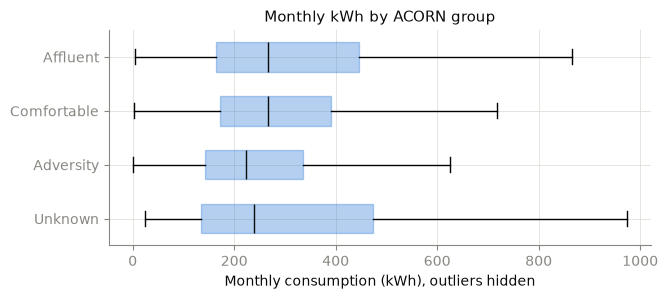

Saved reports/figures/p3_acorn_box.png


In [11]:
ACORN_ORDER = ["Affluent", "Comfortable", "Adversity", "Unknown"]
by_group = con.sql("SELECT acorn_group, kwh FROM monthly").df()

fig, ax = plt.subplots(figsize=(7, 2.8))
box = ax.boxplot([by_group.loc[by_group["acorn_group"] == g, "kwh"] for g in ACORN_ORDER],
                 orientation="horizontal", showfliers=False, patch_artist=True, widths=0.55,
                 medianprops={"color": INK})
for patch in box["boxes"]:
    patch.set_facecolor(COLORS[0]); patch.set_alpha(0.35); patch.set_edgecolor(COLORS[0])
ax.set_yticks(range(1, len(ACORN_ORDER) + 1), ACORN_ORDER)
ax.invert_yaxis()
ax.set_xlabel("Monthly consumption (kWh), outliers hidden")
ax.set_title("Monthly kWh by ACORN group")
save(fig, "p3_acorn_box.png")

**Takeaway.** Affluent households use the most and Adversity the least, but the boxes overlap heavily: the group
shifts the typical level a little and leaves most of the variation unexplained. `Unknown` is a small group, so its
mean is unstable. ACORN is worth keeping as a household-level feature, mainly to help households with little history.

### 3.4 History length and gaps

Lag features need earlier months. A household's months are not always consecutive (Phase 2 dropped incomplete
months), so a lag must check that the earlier month is really the previous calendar month.

In [12]:
con.sql("""
    WITH ordered AS (
        SELECT LCLid, month, LAG(month) OVER (PARTITION BY LCLid ORDER BY month) AS prior_month
        FROM monthly
    )
    SELECT count(*) FILTER (WHERE prior_month IS NOT NULL)                                   AS pairs_checked,
           count(*) FILTER (WHERE month = prior_month + INTERVAL 1 MONTH)                    AS adjacent_pairs,
           count(*) FILTER (WHERE month > prior_month + INTERVAL 1 MONTH)                    AS gaps,
           count(DISTINCT LCLid) FILTER (WHERE month > prior_month + INTERVAL 1 MONTH)       AS households_with_gaps
    FROM ordered
""").df()

,pairs_checked,adjacent_pairs,gaps,households_with_gaps
0,80379,80139,240,175


Gaps are rare, but each one breaks the lag features for the month after it. Section 6 handles this by setting a lag
to NULL unless the earlier month is the exact calendar month required.

## 4. Outliers

### 4.1 Pooled IQR check (first pass, repeated on Std)

The first pass flagged months above the Tukey fence Q3 + 1.5 × IQR, computed over all household-months together.

In [13]:
con.execute(f"""
    CREATE OR REPLACE TABLE fences AS
    SELECT quantile_cont(kwh, 0.25) AS q1, quantile_cont(kwh, 0.75) AS q3,
           quantile_cont(kwh, 0.75) + {IQR_K} * (quantile_cont(kwh, 0.75) - quantile_cont(kwh, 0.25)) AS upper_fence
    FROM monthly
""")
con.execute("""
    CREATE OR REPLACE TABLE household_levels AS
    SELECT LCLid, median(kwh) AS household_median, count(*) AS months FROM monthly GROUP BY 1
""")

con.sql("""
    SELECT round(f.q1, 2) AS q1, round(f.q3, 2) AS q3, round(f.upper_fence, 2) AS upper_fence,
           count(*) FILTER (WHERE m.kwh > f.upper_fence)                                         AS flagged_months,
           round(100.0 * count(*) FILTER (WHERE m.kwh > f.upper_fence) / count(*), 2)            AS flagged_pct,
           count(DISTINCT m.LCLid) FILTER (WHERE m.kwh > f.upper_fence)                          AS households_flagged,
           -- flags that belong to households whose *typical* month is already above the fence
           round(100.0 * count(*) FILTER (WHERE m.kwh > f.upper_fence AND h.household_median > f.upper_fence)
                 / count(*) FILTER (WHERE m.kwh > f.upper_fence), 1)                             AS pct_from_high_households
    FROM monthly AS m CROSS JOIN fences AS f JOIN household_levels AS h USING (LCLid)
    GROUP BY ALL
""").df()

,q1,q3,upper_fence,flagged_months,flagged_pct,households_flagged,pct_from_high_households
0,157.85,389.19,736.19,4657,5.49,676,58.3


**Most pooled flags are not unusual months.** More than half come from households whose *median* month is already
above the fence: big consumers whose every month looks extreme next to everyone else. The pooled check measures
which households are large, not which months are odd. These are real readings, so we keep them.

### 4.2 Within-household check

To find unusual **months**, we compare each month with that household's own history. We use a robust z-score,
0.6745 × (kWh − household median) / MAD, where MAD is the median absolute deviation from the household median.
Median and MAD are not pulled around by the outliers we are looking for, unlike mean and standard deviation.
A month is flagged when |z| > 3.5 (the usual cutoff for this score). Only households with at least 6 months are
checked.

This uses the household's full history, including later months, so it is a **data check, not a feature**: it must
not feed the model.

In [14]:
con.execute(f"""
    CREATE OR REPLACE TABLE robust_z AS
    WITH mad AS (
        SELECT m.LCLid, median(abs(m.kwh - h.household_median)) AS mad
        FROM monthly AS m JOIN household_levels AS h USING (LCLid)
        GROUP BY 1
    )
    SELECT m.LCLid, m.month, m.kwh, h.household_median, mad.mad,
           {MAD_TO_Z} * (m.kwh - h.household_median) / mad.mad AS z
    FROM monthly AS m
    JOIN household_levels AS h USING (LCLid)
    JOIN mad USING (LCLid)
    WHERE h.months >= {MIN_MONTHS_PER_HOUSEHOLD} AND mad.mad > 0
""")

con.sql(f"""
    SELECT count(*)                                                    AS months_checked,
           count(DISTINCT LCLid)                                       AS households_checked,
           count(*) FILTER (WHERE abs(z) > {ROBUST_Z_LIMIT})          AS flagged_months,
           round(100.0 * count(*) FILTER (WHERE abs(z) > {ROBUST_Z_LIMIT}) / count(*), 2) AS flagged_pct,
           count(*) FILTER (WHERE z >  {ROBUST_Z_LIMIT})              AS flagged_high,
           count(*) FILTER (WHERE z < -{ROBUST_Z_LIMIT})              AS flagged_low,
           count(DISTINCT LCLid) FILTER (WHERE abs(z) > {ROBUST_Z_LIMIT}) AS households_flagged,
           -- overlap with the pooled check
           count(*) FILTER (WHERE abs(z) > {ROBUST_Z_LIMIT} AND kwh > (SELECT upper_fence FROM fences)) AS also_pooled_flag
    FROM robust_z
""").df()

,months_checked,households_checked,flagged_months,flagged_pct,flagged_high,flagged_low,households_flagged,also_pooled_flag
0,84666,4393,1731,2.04,1303,428,932,274


In [15]:
con.sql(f"""
    SELECT monthname(month) AS calendar_month,
           count(*) FILTER (WHERE z >  {ROBUST_Z_LIMIT}) AS high_flags,
           count(*) FILTER (WHERE z < -{ROBUST_Z_LIMIT}) AS low_flags
    FROM robust_z GROUP BY month(month), calendar_month ORDER BY month(month)
""").df().set_index("calendar_month").T

calendar_month,January,February,March,April,May,June,July,August,September,October,November,December
high_flags,324,104,138,33,26,23,48,30,33,60,136,348
low_flags,42,24,9,14,21,46,40,78,51,23,33,47


**Takeaway.** The within-household check flags a different, smaller set of months, and few of them overlap with the
pooled flags. High flags gather in winter (a household that switches on electric heating), and low flags peak in
the summer months, when usage drops far below normal (a home left empty for a holiday). These are the months a bill forecast
will get most wrong, and they are the reason the forecast needs a prediction interval. We keep them: they are real
behaviour, and an alert system has to cope with them.

## 5. Daily EDA

The first pass never used `daily.parquet`, but the day-`d` task is built from it. This section asks three questions:
how daily usage behaves, how much of the month is known by day `d`, and how good the simplest projection already is.

### 5.1 Daily consumption, weekdays and holidays

To compare days fairly across households, we divide each day's kWh by the household's mean for that month. A ratio
of 1.10 means 10% above that household's normal day.

In [16]:
con.execute("""
    CREATE OR REPLACE TABLE daily_d AS
    SELECT LCLid,
           date_trunc('month', day)::DATE      AS month,
           day,
           extract(day FROM day)::INT          AS dom,            -- day of month
           extract(day FROM last_day(day))::INT AS days_in_month,
           isodow(day)                         AS iso_dow,        -- 1 = Monday ... 7 = Sunday
           isodow(day) >= 6                    AS is_weekend,
           is_holiday,
           kwh,
           temp_mean
    FROM daily
""")

con.sql("""
    SELECT count(*) AS household_days, round(avg(kwh), 2) AS mean_kwh, round(median(kwh), 2) AS median_kwh,
           round(stddev_samp(kwh), 2) AS sd_kwh, round(min(kwh), 3) AS min_kwh, round(max(kwh), 2) AS max_kwh,
           count(*) FILTER (WHERE is_holiday) AS holiday_days
    FROM daily_d
""").df()

,household_days,mean_kwh,median_kwh,sd_kwh,min_kwh,max_kwh,holiday_days
0,2586554,10.36,7.96,9.35,0.001,332.56,59837


In [17]:
con.execute("""
    CREATE OR REPLACE TABLE day_ratios AS
    SELECT *, kwh / avg(kwh) OVER (PARTITION BY LCLid, month) AS ratio
    FROM daily_d
""")

dow = con.sql("""
    SELECT iso_dow, dayname(min(day)) AS weekday, avg(ratio) AS mean_ratio
    FROM day_ratios WHERE NOT is_holiday GROUP BY iso_dow ORDER BY iso_dow
""").df()

day_type = con.sql("""
    SELECT CASE WHEN is_holiday THEN 'bank holiday' WHEN is_weekend THEN 'weekend' ELSE 'normal weekday' END AS day_type,
           count(*) AS household_days, round(avg(ratio), 3) AS mean_ratio
    FROM day_ratios GROUP BY 1 ORDER BY mean_ratio
""").df()
display(dow.round(3))
day_type

,iso_dow,weekday,mean_ratio
0,1,Monday,0.996
1,2,Tuesday,0.984
2,3,Wednesday,0.984
3,4,Thursday,0.981
4,5,Friday,0.981
5,6,Saturday,1.013
6,7,Sunday,1.057


,day_type,household_days,mean_ratio
0,normal weekday,1790457,0.985
1,bank holiday,59837,1.018
2,weekend,736260,1.035


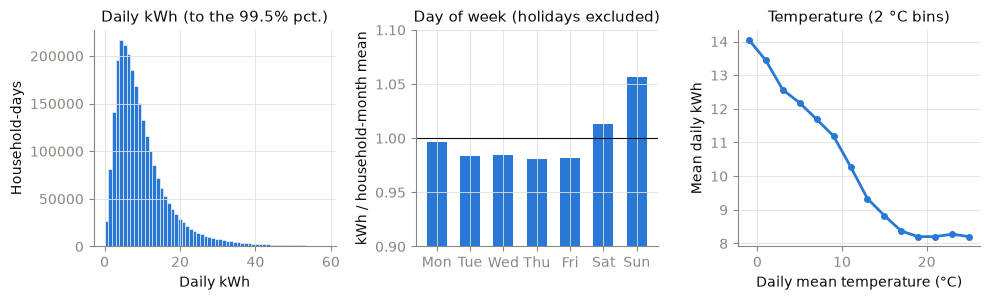

Saved reports/figures/p3_daily_patterns.png


In [18]:
temp_bins = con.sql(f"""
    SELECT floor(temp_mean / {TEMP_BIN_C}) * {TEMP_BIN_C} + {TEMP_BIN_C} / 2 AS temp_c,
           avg(kwh) AS mean_kwh, count(*) AS household_days
    FROM daily_d GROUP BY 1 HAVING count(*) >= 1000 ORDER BY 1
""").df()
daily_kwh = con.sql(f"""
    SELECT kwh FROM daily_d
    WHERE kwh <= (SELECT quantile_cont(kwh, {HIST_CLIP_PCT}) FROM daily_d)
""").df()["kwh"]

fig, axes = plt.subplots(1, 3, figsize=(10, 3.1))
axes[0].hist(daily_kwh, bins=60, color=COLORS[0], edgecolor="white", linewidth=0.4)
axes[0].set_xlabel("Daily kWh"); axes[0].set_ylabel("Household-days")
axes[0].set_title(f"Daily kWh (to the {HIST_CLIP_PCT:.1%} pct.)")

axes[1].bar(dow["weekday"].str[:3], dow["mean_ratio"], color=COLORS[0], width=0.6)
axes[1].axhline(1, color=INK, linewidth=0.8)
axes[1].set_ylim(0.9, 1.1)
axes[1].set_ylabel("kWh / household-month mean")
axes[1].set_title("Day of week (holidays excluded)")

axes[2].plot(temp_bins["temp_c"], temp_bins["mean_kwh"], marker="o", markersize=4, color=COLORS[0])
axes[2].set_xlabel("Daily mean temperature (°C)"); axes[2].set_ylabel("Mean daily kWh")
axes[2].set_title(f"Temperature ({TEMP_BIN_C} °C bins)")
fig.tight_layout()
save(fig, "p3_daily_patterns.png")

**Takeaway.** Daily kWh is right-skewed like the monthly totals. Weekends and bank holidays run above normal
weekdays (people are at home), so the number of weekend days and holidays still to come in a month carries
information about the remaining kWh. Daily usage falls steadily as temperature rises and flattens out in warm
weather, when there is no heating left to switch off.

### 5.2 How much of the month is known by day d

For each household-month we take the share of the month's kWh already used by day `d`. If every day were the same,
the share would be `d / days in month`. The gap between the two tells us how much the first days differ from the rest.

In [19]:
con.execute("""
    CREATE OR REPLACE TABLE cumulative AS
    SELECT LCLid, month, dom, days_in_month,
           sum(kwh) OVER (PARTITION BY LCLid, month ORDER BY dom) AS kwh_to_date,
           sum(kwh) OVER (PARTITION BY LCLid, month)              AS month_kwh
    FROM daily_d
""")

share = con.sql(f"""
    SELECT dom AS d,
           median(kwh_to_date / month_kwh)              AS median_share,
           quantile_cont(kwh_to_date / month_kwh, 0.10) AS p10,
           quantile_cont(kwh_to_date / month_kwh, 0.90) AS p90,
           avg(dom / days_in_month)                     AS uniform_share
    FROM cumulative WHERE dom <= {CURVE_MAX_D} GROUP BY dom ORDER BY dom
""").df()
share[share["d"].isin(D_VALUES)].round(3)

,d,median_share,p10,p90,uniform_share
6,7,0.228,0.190,0.268,0.230
13,14,0.457,0.407,0.514,0.459
20,21,0.686,0.639,0.745,0.689


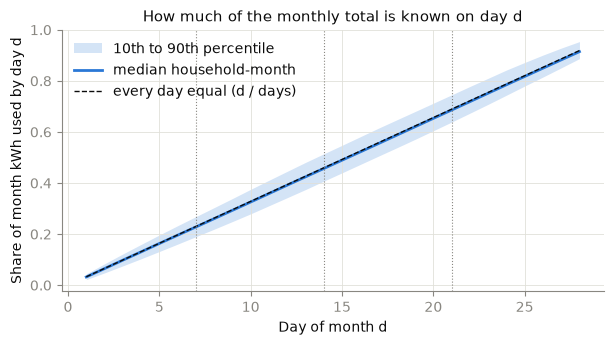

Saved reports/figures/p3_share_by_day.png


In [20]:
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.fill_between(share["d"], share["p10"], share["p90"], color=COLORS[0], alpha=0.2, linewidth=0, label="10th to 90th percentile")
ax.plot(share["d"], share["median_share"], color=COLORS[0], label="median household-month")
ax.plot(share["d"], share["uniform_share"], color=INK, linestyle="--", linewidth=1, label="every day equal (d / days)")
for d in D_VALUES:
    ax.axvline(d, color=MUTED, linewidth=0.8, linestyle=":")
ax.set_xlabel("Day of month d")
ax.set_ylabel("Share of month kWh used by day d")
ax.set_title("How much of the monthly total is known on day d")
ax.legend(frameon=False, loc="upper left")
save(fig, "p3_share_by_day.png")

**Takeaway.** The median curve follows the "every day equal" line closely, so a day-`d` total scaled up to the full
month is a sensible starting point. The band around it is the problem: at the same `d`, one household-month in five sits
more than about 4 to 5 percentage points away from the median share, in either direction. That spread does not shrink
with `d`, but the part of the month still unknown does, so the error in pounds falls as `d` grows (section 5.3). The
model has to explain that spread with history, calendar and weather.

### 5.3 Benchmarks: how good is the naive run-rate projection?

The **run-rate projection** scales the month-to-date total up to the full month: `kwh_to_date / d × days in month`.
We compare it with the two other Phase 1 benchmarks, **last month's bill** and **the same month last year**, which
do not depend on `d`.

The error measure is the **absolute percentage error** of the projected month total, |projected − actual| / actual,
summarised by its median. The median is used because a few near-empty months (actual close to 0) make the
percentage, and its mean, explode. We also give the mean absolute error in pounds.

The last-year benchmark only exists for months that have the same month a year earlier, so all three are compared
on the **same household-months**: those with both a previous month and a same-month-last-year value.

In [21]:
con.execute("""
    CREATE OR REPLACE TABLE monthly_lags AS
    WITH history AS (
        SELECT LCLid, month, kwh, acorn_group, days,
               LAG(month, 1) OVER w AS month_1, LAG(month, 2) OVER w AS month_2, LAG(month, 3) OVER w AS month_3,
               LAG(kwh, 1)   OVER w AS kwh_1,   LAG(kwh, 2)   OVER w AS kwh_2,   LAG(kwh, 3)   OVER w AS kwh_3
        FROM monthly
        WINDOW w AS (PARTITION BY LCLid ORDER BY month)
    )
    SELECT h.LCLid, h.month, h.kwh AS month_kwh, h.acorn_group, h.days AS days_in_month,
           -- a lag counts only when the earlier row is the exact calendar month needed (gaps make it NULL)
           CASE WHEN h.month_1 = h.month - INTERVAL 1 MONTH THEN h.kwh_1 END AS previous_month_kwh,
           CASE WHEN h.month_1 = h.month - INTERVAL 1 MONTH
                 AND h.month_2 = h.month - INTERVAL 2 MONTH
                 AND h.month_3 = h.month - INTERVAL 3 MONTH
                THEN (h.kwh_1 + h.kwh_2 + h.kwh_3) / 3 END                AS rolling_3month_kwh,
           -- LAG(12) would land on the wrong month after a gap, so the 12-month lag is a direct lookup
           ly.kwh AS same_month_last_year_kwh
    FROM history AS h
    LEFT JOIN monthly AS ly ON ly.LCLid = h.LCLid AND ly.month = (h.month - INTERVAL 12 MONTH)::DATE
""")

con.sql("""
    SELECT count(*) AS household_months,
           count(previous_month_kwh)       AS with_previous_month,
           count(rolling_3month_kwh)       AS with_rolling_3month,
           count(same_month_last_year_kwh) AS with_same_month_last_year,
           count(*) FILTER (WHERE previous_month_kwh IS NOT NULL AND same_month_last_year_kwh IS NOT NULL) AS with_both_benchmarks,
           min(month) FILTER (WHERE same_month_last_year_kwh IS NOT NULL) AS first_month_with_last_year
    FROM monthly_lags
""").df()

,household_months,with_previous_month,with_rolling_3month,with_same_month_last_year,with_both_benchmarks,first_month_with_last_year
0,84807,80139,71002,32588,32491,2012-12-01


Most households joined between April and July 2012, so a same-month-last-year value only exists from December 2012
on, and only for 38% of household-months. In Phase 4 that benchmark can only be scored on 2013 months.

In [22]:
runrate = con.sql(f"""
    WITH c AS (
        SELECT c.*, l.previous_month_kwh IS NOT NULL AND l.same_month_last_year_kwh IS NOT NULL AS common
        FROM cumulative AS c JOIN monthly_lags AS l USING (LCLid, month)
        WHERE c.dom <= {CURVE_MAX_D}
    )
    SELECT dom AS d,
           median(abs(kwh_to_date / dom * days_in_month - month_kwh) / month_kwh)                  AS mdape_all,
           median(abs(kwh_to_date / dom * days_in_month - month_kwh) / month_kwh) FILTER (WHERE common) AS mdape_common,
           avg(abs(kwh_to_date / dom * days_in_month - month_kwh)) FILTER (WHERE common) * {TARIFF_GBP_PER_KWH} AS mae_gbp_common
    FROM c GROUP BY dom ORDER BY dom
""").df()

benchmarks = con.sql(f"""
    SELECT 'last month' AS benchmark,
           median(abs(previous_month_kwh - month_kwh) / month_kwh) AS mdape,
           avg(abs(previous_month_kwh - month_kwh)) * {TARIFF_GBP_PER_KWH} AS mae_gbp
    FROM monthly_lags WHERE previous_month_kwh IS NOT NULL AND same_month_last_year_kwh IS NOT NULL
    UNION ALL
    SELECT 'same month last year',
           median(abs(same_month_last_year_kwh - month_kwh) / month_kwh),
           avg(abs(same_month_last_year_kwh - month_kwh)) * {TARIFF_GBP_PER_KWH}
    FROM monthly_lags WHERE previous_month_kwh IS NOT NULL AND same_month_last_year_kwh IS NOT NULL
""").df()

display(runrate[runrate["d"].isin(D_VALUES)].round(3))
benchmarks.round(3)

,d,mdape_all,mdape_common,mae_gbp_common
6,7,0.068,0.068,5.041
13,14,0.043,0.042,3.231
20,21,0.026,0.025,1.932


,benchmark,mdape,mae_gbp
0,last month,0.093,6.684
1,same month last year,0.120,8.459


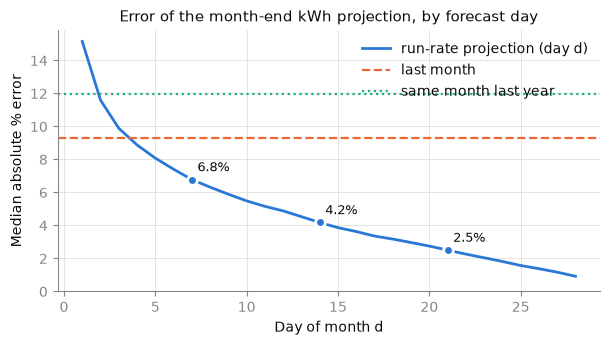

Saved reports/figures/p3_runrate_error.png


In [23]:
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(runrate["d"], 100 * runrate["mdape_common"], color=COLORS[0], label="run-rate projection (day d)")
for (_, row), color, style in zip(benchmarks.iterrows(), [COLORS[1], COLORS[2]], ["--", ":"]):
    ax.axhline(100 * row["mdape"], color=color, linestyle=style, linewidth=1.6, label=row["benchmark"])
for d in D_VALUES:
    value = 100 * runrate.loc[runrate["d"] == d, "mdape_common"].item()
    ax.plot(d, value, "o", color=COLORS[0], markersize=7, markeredgecolor="white", markeredgewidth=2)
    ax.annotate(f"{value:.1f}%", (d, value), textcoords="offset points", xytext=(4, 6), fontsize=9)
ax.set_xlabel("Day of month d")
ax.set_ylabel("Median absolute % error")
ax.set_ylim(bottom=0)
ax.set_title("Error of the month-end kWh projection, by forecast day")
ax.legend(frameon=False)
save(fig, "p3_runrate_error.png")

**Takeaway.** The run-rate projection improves quickly as `d` grows. From `d` = 4 on it beats the last-month
benchmark, and by `d` = 14 it is far better than either history-only benchmark. This is the bar the Phase 4 model has
to clear: a model that cannot beat a straight-line projection of the month so far adds nothing. It also says that
`kwh_to_date` is the dominant input, and the history and calendar features matter most at small `d`.

The history-only benchmarks ignore the days already recorded, which is why they cannot improve with `d`.

## 6. Build the day-d dataset

One row per **household × month × d**, for each candidate `d` in `D_VALUES`. The rule that keeps the data honest:
**a feature may use only days 1..d of the target month, or earlier months.** The days after `d` appear only in the
targets.

| Group | Features |
|---|---|
| Month to date | `kwh_to_date`, `daily_mean_to_date`, `last7_mean_kwh`, `run_rate_kwh`, `days_elapsed` (= d), `days_remaining` |
| Earlier months | `previous_month_kwh`, `rolling_3month_kwh`, `same_month_last_year_kwh` |
| Calendar (known in advance) | `month_sin`, `month_cos`, `weekend_days_remaining`, `holidays_remaining` |
| Weather | `temp_mean_to_date` (days 1..d only) |
| Household | `acorn_comfortable`, `acorn_adversity`, `acorn_unknown` (Affluent is the reference group) |
| Targets | `remaining_kwh` (days d+1..end, the model target), `month_kwh`, `final_bill_gbp` |
| Benchmarks | `runrate_bill_gbp`, `last_month_bill_gbp`, `same_month_ly_bill_gbp` |

Choices that differ from the first pass:
- **Month as sine and cosine.** A month number 1..12 tells a model December (12) is far from January (1). Placing the
  months on a circle keeps neighbours next to each other. This replaces `month_number`, `quarter` and the season
  dummies, which all encoded the same thing.
- **One ACORN category dropped.** The four ACORN dummies always sum to 1, so a linear model with an intercept cannot
  separate their effects. Affluent, the largest group, becomes the baseline.
- **Temperature to date only.** The monthly `temp_mean` includes days after `d`, which the forecast cannot know.
- **No tariff column.** Every row is Std.
- **No scaling here.** Scaling is fitted in Phase 4 on the training period only, so test months cannot leak into it.

In [24]:
con.execute("CREATE OR REPLACE TABLE d_values AS SELECT unnest(?::INT[]) AS d", [D_VALUES])

con.execute(f"""
    COPY (
        WITH to_date AS (
            SELECT dd.LCLid, dd.month, dv.d,
                   sum(dd.kwh)       FILTER (WHERE dd.dom <= dv.d)                        AS kwh_to_date,
                   avg(dd.kwh)       FILTER (WHERE dd.dom <= dv.d)                        AS daily_mean_to_date,
                   avg(dd.kwh)       FILTER (WHERE dd.dom BETWEEN dv.d - 6 AND dv.d)      AS last7_mean_kwh,
                   avg(dd.temp_mean) FILTER (WHERE dd.dom <= dv.d)                        AS temp_mean_to_date,
                   -- calendar facts about the rest of the month: known in advance, not usage
                   count(*)          FILTER (WHERE dd.dom > dv.d AND dd.is_weekend)       AS weekend_days_remaining,
                   count(*)          FILTER (WHERE dd.dom > dv.d AND dd.is_holiday)       AS holidays_remaining,
                   -- target: the part of the month still to come
                   sum(dd.kwh)       FILTER (WHERE dd.dom > dv.d)                         AS remaining_kwh
            FROM daily_d AS dd CROSS JOIN d_values AS dv
            GROUP BY ALL
        )
        SELECT
            t.LCLid, t.month, t.d,
            -- month to date
            t.kwh_to_date,
            t.d                                        AS days_elapsed,
            l.days_in_month - t.d                      AS days_remaining,
            t.daily_mean_to_date,
            t.last7_mean_kwh,
            t.kwh_to_date / t.d * l.days_in_month      AS run_rate_kwh,
            -- earlier months
            l.previous_month_kwh,
            l.rolling_3month_kwh,
            l.same_month_last_year_kwh,
            -- calendar
            sin(2 * pi() * (month(t.month) - 1) / 12)  AS month_sin,
            cos(2 * pi() * (month(t.month) - 1) / 12)  AS month_cos,
            t.weekend_days_remaining,
            t.holidays_remaining,
            -- weather
            t.temp_mean_to_date,
            -- household (Affluent = reference)
            l.acorn_group,
            (l.acorn_group = 'Comfortable')::INT       AS acorn_comfortable,
            (l.acorn_group = 'Adversity')::INT         AS acorn_adversity,
            (l.acorn_group = 'Unknown')::INT           AS acorn_unknown,
            -- targets
            t.remaining_kwh,
            l.month_kwh,
            l.month_kwh * {TARIFF_GBP_PER_KWH}         AS final_bill_gbp,
            -- benchmarks, as bills, so Phase 4 can score them directly
            t.kwh_to_date / t.d * l.days_in_month * {TARIFF_GBP_PER_KWH} AS runrate_bill_gbp,
            l.previous_month_kwh * {TARIFF_GBP_PER_KWH}                   AS last_month_bill_gbp,
            l.same_month_last_year_kwh * {TARIFF_GBP_PER_KWH}             AS same_month_ly_bill_gbp
        FROM to_date AS t
        JOIN monthly_lags AS l USING (LCLid, month)
        ORDER BY t.LCLid, t.month, t.d
    ) TO '{FEATURES_PARQUET}' (FORMAT parquet)
""")

con.execute(f"CREATE OR REPLACE VIEW features AS SELECT * FROM '{FEATURES_PARQUET}'")
print("Saved", FEATURES_PARQUET.relative_to(ROOT))
con.sql("SELECT d, count(*) AS row_count, count(DISTINCT LCLid) AS households FROM features GROUP BY d ORDER BY d").df()

Saved data/processed/features_day_d.parquet


,d,row_count,households
0,7,84807,4428
1,14,84807,4428
2,21,84807,4428


At `d` = 7 the last-7-days mean and the month-to-date mean are the same number. They only differ for larger `d`,
where the last week can show a change in usage partway through the month.

### 6.1 Feature availability

Only the earlier-month features can be missing. They are the same for every `d`, so we count them at one `d`.

In [25]:
feature_columns = [c for c in con.sql("DESCRIBE features").df()["column_name"]
                   if c not in ("LCLid", "month", "d", "acorn_group")]

availability = con.sql(f"""
    SELECT {", ".join(f"count({c}) AS {c}" for c in feature_columns)}, count(*) AS total
    FROM features WHERE d = {D_VALUES[0]}
""").df().T.rename(columns={0: "available"})
total = availability.loc["total", "available"]
availability["missing"] = total - availability["available"]
availability["available_pct"] = (100 * availability["available"] / total).round(2)
availability.drop(index="total")

,available,missing,available_pct
kwh_to_date,84807,0,100.00
days_elapsed,84807,0,100.00
days_remaining,84807,0,100.00
daily_mean_to_date,84807,0,100.00
last7_mean_kwh,84807,0,100.00
run_rate_kwh,84807,0,100.00
previous_month_kwh,80139,4668,94.50
rolling_3month_kwh,71002,13805,83.72
same_month_last_year_kwh,32588,52219,38.43
month_sin,84807,0,100.00


Missing lags are left as NULL, not filled in. Filling them with, say, the household mean would use months that come
after the target month. Phase 4 decides how to handle them: models that accept missing values (gradient-boosted
trees) can use them directly; linear models need a missing-value indicator, or separate models by history length.

### 6.2 Feature summary and relationships

Statistics for the features at each candidate `d`, then a correlation heatmap at `d` = 14.

In [26]:
NUMERIC_FEATURES = ["kwh_to_date", "daily_mean_to_date", "last7_mean_kwh", "run_rate_kwh",
                    "previous_month_kwh", "rolling_3month_kwh", "same_month_last_year_kwh",
                    "month_sin", "month_cos", "weekend_days_remaining", "holidays_remaining", "temp_mean_to_date"]
TARGETS = ["remaining_kwh", "final_bill_gbp"]

con.sql(" UNION ALL ".join(f"""
    SELECT '{c}' AS feature, d, avg({c}) AS mean, median({c}) AS median, stddev_samp({c}) AS sd,
           min({c}) AS min, max({c}) AS max
    FROM features GROUP BY d""" for c in NUMERIC_FEATURES + TARGETS) + " ORDER BY feature, d").df().round(2)

,feature,d,mean,median,sd,min,max
0,daily_mean_to_date,7,10.29,8.11,8.73,0.00,253.18
1,daily_mean_to_date,14,10.35,8.17,8.71,0.02,214.21
2,daily_mean_to_date,21,10.35,8.19,8.64,0.04,178.13
3,final_bill_gbp,7,44.95,35.61,37.25,0.18,908.58
4,final_bill_gbp,14,44.95,35.61,37.25,0.18,908.58
5,final_bill_gbp,21,44.95,35.61,37.25,0.18,908.58
6,holidays_remaining,7,0.40,0.00,0.66,0.00,2.00
7,holidays_remaining,14,0.39,0.00,0.66,0.00,2.00
8,holidays_remaining,21,0.39,0.00,0.66,0.00,2.00
9,kwh_to_date,7,72.01,56.80,61.09,0.01,1772.26


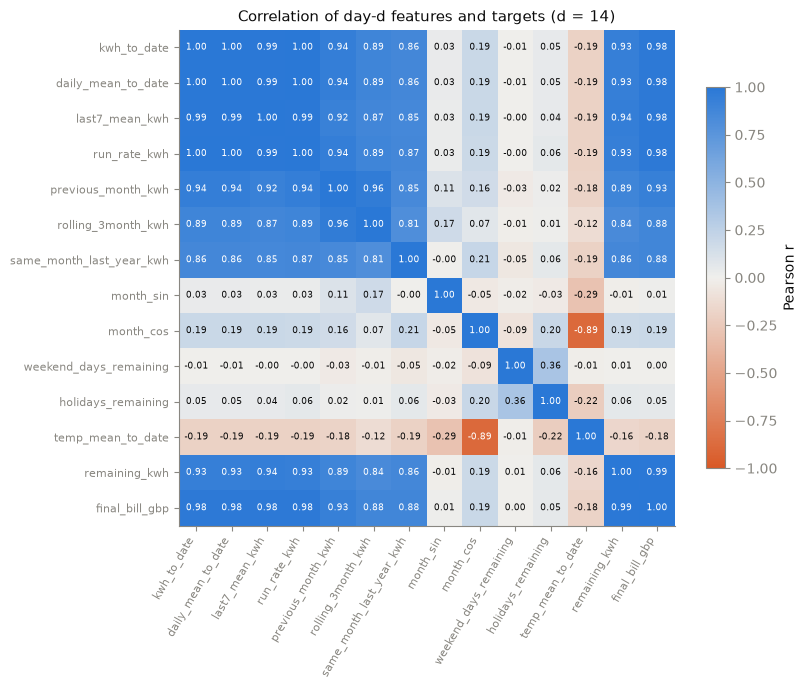

Saved reports/figures/p3_feature_corr.png


In [27]:
corr_cols = NUMERIC_FEATURES + TARGETS
# Pairwise correlations on the rows where both columns exist (DuckDB's corr skips NULL pairs)
corr = np.array([[con.sql(f"SELECT corr({a}, {b}) FROM features WHERE d = {CORR_D}").fetchone()[0]
                  for b in corr_cols] for a in corr_cols])

fig, ax = plt.subplots(figsize=(8, 6.6))
im = ax.imshow(corr, cmap=CORR_CMAP, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_cols)), corr_cols, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(corr_cols)), corr_cols, fontsize=8)
ax.grid(False)
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        ax.text(j, i, f"{corr[i, j]:.2f}", ha="center", va="center", fontsize=6.5,
                color="white" if abs(corr[i, j]) > 0.75 else INK)
fig.colorbar(im, ax=ax, shrink=0.75, label="Pearson r")
ax.set_title(f"Correlation of day-d features and targets (d = {CORR_D})")
save(fig, "p3_feature_corr.png")

In [28]:
target_corr = con.sql(" UNION ALL ".join(f"""
    SELECT '{c}' AS feature, d, corr({c}, remaining_kwh) AS r_remaining_kwh, corr({c}, final_bill_gbp) AS r_final_bill
    FROM features GROUP BY d""" for c in NUMERIC_FEATURES)).df()
target_corr.pivot(index="feature", columns="d", values="r_remaining_kwh").round(3)

d,7,14,21
feature,,,
daily_mean_to_date,0.927,0.932,0.930
holidays_remaining,0.056,0.059,0.078
kwh_to_date,0.927,0.932,0.930
last7_mean_kwh,0.927,0.938,0.940
month_cos,0.190,0.187,0.181
month_sin,-0.002,-0.014,-0.024
previous_month_kwh,0.910,0.889,0.866
rolling_3month_kwh,0.863,0.843,0.824
run_rate_kwh,0.928,0.934,0.934


**Within-household check (first pass, redone on Std).** The pooled correlation between last month's kWh and this
month's kWh mixes two things: big households stay big, and a household's own months move together. The second part
is what helps a per-household forecast. We repeat the first pass's per-household correlation for households with at
least 6 valid previous-month values. Since the bill is kWh times a fixed rate, this is also the correlation with the
bill.

In [29]:
con.sql(f"""
    WITH pooled AS (
        SELECT corr(previous_month_kwh, month_kwh) AS r FROM monthly_lags
    ),
    per_household AS (
        SELECT LCLid, corr(previous_month_kwh, month_kwh) AS r
        FROM monthly_lags GROUP BY LCLid
        HAVING count(previous_month_kwh) >= {MIN_MONTHS_PER_HOUSEHOLD}
    )
    SELECT round((SELECT r FROM pooled), 3)  AS pooled_r,
           count(*)                           AS households,
           round(median(r), 3)                AS median_within_household_r,
           count(*) FILTER (WHERE r < 0)      AS households_negative_r
    FROM per_household
""").df()

,pooled_r,households,median_within_household_r,households_negative_r
0,0.928,4366,0.577,243


**Takeaway.**
- `kwh_to_date`, `run_rate_kwh` and the daily means are almost the same signal, and all correlate strongly with the
  final bill. They are redundant with each other, which matters for linear models (Phase 4 should keep one or use
  regularisation) but not for tree models.
- For the **remaining** kWh, the history features are almost as strong as the month-to-date ones at `d` = 7 and fall
  behind as `d` grows, while the last-7-days mean gains (the rest of the month looks like the part just seen).
- The month cosine and temperature to date are strongly related to each other (both measure winter), so they overlap.
- The pooled correlation with last month is much higher than the typical within-household one: much of the pooled
  value says "big households stay big". The within-household value is still clearly positive, so recent history helps.
- Temperature to date and the month's position on the calendar carry the seasonal signal; the weekend and holiday
  counts are weak on their own but cheap and leak-free.

## 7. Encoding and scaling

- **Encoding.** ACORN group is one-hot encoded with Affluent dropped as the reference. The month is encoded as a
  sine/cosine pair. The text column `acorn_group` stays in the file for readability; it is not a model input.
- **Scaling.** The features sit on very different ranges (below), so models that are sensitive to scale (regularised
  linear models, k-nearest neighbours, neural networks) need scaling. We **do not scale here**: a scaler learns means
  and spreads, and fitting it on all months would leak information from the test period. Phase 4 fits it on the
  training months only. Given the skew and the outliers in section 4, a robust scaler (median and IQR) or a log
  transform of the kWh columns is worth trying.

In [30]:
con.sql(" UNION ALL ".join(f"SELECT '{c}' AS feature, min({c}) AS min, max({c}) AS max FROM features"
                           for c in NUMERIC_FEATURES + TARGETS)).df().round(2)

,feature,min,max
0,kwh_to_date,0.01,3740.76
1,daily_mean_to_date,0.00,253.18
2,last7_mean_kwh,0.00,285.99
3,run_rate_kwh,0.03,7848.59
4,previous_month_kwh,1.29,6385.89
5,rolling_3month_kwh,5.50,3540.41
6,same_month_last_year_kwh,3.64,6385.89
7,month_sin,-1.00,1.00
8,month_cos,-1.00,1.00
9,weekend_days_remaining,2.00,8.00


## 8. Final checks

Each check counts rows that break a rule. Every count should be 0; a failure stops the notebook.

The leakage check rebuilds every month-to-date feature from a copy of the daily table cut off at day `d`. If any
feature had used a day after `d`, the rebuilt value would differ.

In [31]:
expected_rows = con.sql("SELECT count(*) FROM monthly").fetchone()[0] * len(D_VALUES)

con.execute("""
    CREATE OR REPLACE TABLE rebuilt AS
    SELECT dd.LCLid, dd.month, dv.d,
           sum(dd.kwh) AS kwh_to_date, avg(dd.kwh) AS daily_mean_to_date,
           avg(dd.kwh) FILTER (WHERE dd.dom > dv.d - 7) AS last7_mean_kwh,
           avg(dd.temp_mean) AS temp_mean_to_date
    FROM daily_d AS dd JOIN d_values AS dv ON dd.dom <= dv.d     -- days after d are never joined
    GROUP BY ALL
""")

checks = {
    "duplicate (household, month, d) rows":
        "SELECT count(*) FROM (SELECT LCLid, month, d FROM features GROUP BY ALL HAVING count(*) > 1)",
    "row count differs from household-months x candidate d":
        f"SELECT abs(count(*) - {expected_rows}) FROM features",
    "kwh_to_date + remaining_kwh differs from month_kwh":
        "SELECT count(*) FROM features WHERE abs(kwh_to_date + remaining_kwh - month_kwh) > 1e-6",
    "final bill differs from the Phase 2 monthly bill":
        "SELECT count(*) FROM features f JOIN monthly m USING (LCLid, month) WHERE abs(f.final_bill_gbp - m.bill_gbp) > 1e-6",
    "month-to-date feature uses a day after d (rebuilt from truncated data)":
        """SELECT count(*) FROM features f JOIN rebuilt r USING (LCLid, month, d)
           WHERE abs(f.kwh_to_date - r.kwh_to_date) > 1e-9 OR abs(f.daily_mean_to_date - r.daily_mean_to_date) > 1e-9
              OR abs(f.last7_mean_kwh - r.last7_mean_kwh) > 1e-9 OR abs(f.temp_mean_to_date - r.temp_mean_to_date) > 1e-9""",
    "rows from a tariff other than Std":
        f"SELECT count(*) FROM features f JOIN monthly_all m USING (LCLid, month) WHERE m.tariff <> '{TARIFF_SCOPE}'",
    "missing values in month-to-date, calendar, weather or target columns":
        """SELECT count(*) FROM features WHERE kwh_to_date IS NULL OR last7_mean_kwh IS NULL OR temp_mean_to_date IS NULL
           OR month_sin IS NULL OR remaining_kwh IS NULL OR final_bill_gbp IS NULL OR acorn_group IS NULL""",
    "previous month present but not the calendar month before":
        """SELECT count(*) FROM features f JOIN monthly m
             ON m.LCLid = f.LCLid AND m.month = (f.month - INTERVAL 1 MONTH)::DATE
           WHERE f.previous_month_kwh IS NOT NULL AND abs(f.previous_month_kwh - m.kwh) > 1e-9""",
    "previous month value present without a previous calendar month":
        """SELECT count(*) FROM features f
           WHERE f.previous_month_kwh IS NOT NULL AND NOT EXISTS (
               SELECT 1 FROM monthly m WHERE m.LCLid = f.LCLid AND m.month = (f.month - INTERVAL 1 MONTH)::DATE)""",
    "ACORN dummies sum above 1":
        "SELECT count(*) FROM features WHERE acorn_comfortable + acorn_adversity + acorn_unknown > 1",
}

for name, sql in checks.items():
    problems = con.sql(sql).fetchone()[0]
    print(f"{'OK  ' if problems == 0 else 'FAIL'}  {name}: {problems}")
    assert problems == 0, f"Check failed: {name}"

OK    duplicate (household, month, d) rows: 0
OK    row count differs from household-months x candidate d: 0
OK    kwh_to_date + remaining_kwh differs from month_kwh: 0
OK    final bill differs from the Phase 2 monthly bill: 0
OK    month-to-date feature uses a day after d (rebuilt from truncated data): 0
OK    rows from a tariff other than Std: 0
OK    missing values in month-to-date, calendar, weather or target columns: 0
OK    previous month present but not the calendar month before: 0
OK    previous month value present without a previous calendar month: 0
OK    ACORN dummies sum above 1: 0


### 8.1 Spot check by hand

The checks above are SQL against SQL. Here one household-month is recomputed in pandas straight from its daily rows,
at each `d`, and compared with the saved features. We pick the first household-month (by ID and month) that has all
three lag features.

In [32]:
spot = con.sql("""
    SELECT LCLid, month FROM features
    WHERE previous_month_kwh IS NOT NULL AND rolling_3month_kwh IS NOT NULL AND same_month_last_year_kwh IS NOT NULL
    ORDER BY LCLid, month LIMIT 1
""").fetchone()
hh, month = spot
days = con.execute("SELECT day, kwh, temp_mean, is_holiday FROM daily WHERE LCLid = ? AND date_trunc('month', day) = ? ORDER BY day",
                   [hh, month]).df()
months = con.execute("SELECT month, kwh FROM monthly WHERE LCLid = ?", [hh]).df()
months = pd.Series(months["kwh"].values, index=pd.to_datetime(months["month"]))
saved = con.execute("SELECT * FROM features WHERE LCLid = ? AND month = ? ORDER BY d", [hh, month]).df().set_index("d")
days["day"] = pd.to_datetime(days["day"])
print(f"Household {hh}, month {month:%Y-%m}, {len(days)} days")

for d in D_VALUES:
    known, rest = days.iloc[:d], days.iloc[d:]
    by_hand = {
        "kwh_to_date": known["kwh"].sum(),
        "daily_mean_to_date": known["kwh"].mean(),
        "last7_mean_kwh": known["kwh"].iloc[-7:].mean(),
        "temp_mean_to_date": known["temp_mean"].mean(),
        "weekend_days_remaining": (rest["day"].dt.dayofweek >= 5).sum(),
        "holidays_remaining": rest["is_holiday"].sum(),
        "remaining_kwh": rest["kwh"].sum(),
    }
    for col, value in by_hand.items():
        assert np.isclose(saved.loc[d, col], value), f"d={d}: {col} saved {saved.loc[d, col]} vs by hand {value}"
    print(f"d={d}: all {len(by_hand)} month-to-date values match")

m = pd.Timestamp(month)
prev = [months[m - pd.DateOffset(months=k)] for k in (1, 2, 3)]
assert np.isclose(saved["previous_month_kwh"].iloc[0], prev[0])
assert np.isclose(saved["rolling_3month_kwh"].iloc[0], sum(prev) / 3)
assert np.isclose(saved["same_month_last_year_kwh"].iloc[0], months[m - pd.DateOffset(months=12)])
print("Lag features match")
saved.T

Household MAC000002, month 2013-11, 30 days
d=7: all 7 month-to-date values match
d=14: all 7 month-to-date values match
d=21: all 7 month-to-date values match
Lag features match


d,7,14,21
LCLid,MAC000002,MAC000002,MAC000002
month,2013-11-01 00:00:00,2013-11-01 00:00:00,2013-11-01 00:00:00
kwh_to_date,93.596,228.934,311.704
days_elapsed,7,14,21
days_remaining,23,16,9
daily_mean_to_date,13.370857,16.352429,14.843048
last7_mean_kwh,13.370857,19.334,11.824286
run_rate_kwh,401.125714,490.572857,445.291428
previous_month_kwh,378.171,378.171,378.171
rolling_3month_kwh,323.191333,323.191333,323.191333


## 9. Insights for Phase 4

1. **The run-rate projection is the bar to beat.** Its median error falls fast with `d` and is below both the
   last-month and last-year benchmarks from day 4 on. Phase 4 should report every model against it at each `d`.
2. **`kwh_to_date` dominates; history matters most early in the month.** Model the **remaining** kWh rather than the
   whole month, so the known part is never re-predicted, and expect history features to matter most at `d` = 7.
3. **Households differ more than months do.** Pooled correlations overstate how predictable a household is from its
   own past. This supports comparing pooled and per-household models (the secondary question) and scoring errors per
   household, not only overall.
4. **Seasonality is strong and temperature-driven.** Keep the cyclical month encoding and temperature to date.
5. **Usage is skewed and has real unusual months.** Use robust error measures (median, MAE in pounds), consider a
   log target or robust scaling, and use the spread of unusual months to size the prediction interval.
6. **Same-month-last-year exists only from December 2012.** A time-based split must leave 2013 months in the test set
   for that benchmark to be scored, and a model cannot rely on that feature for 2012 rows.
7. **Weekend and holiday effects are real but small.** Keep the remaining-weekend/holiday counts; they cost nothing and
   use only the calendar.